In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm


import os
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_dataset

In [5]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print(device)

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

cuda
NVIDIA GeForce RTX 4090


In [6]:
#Import SAM2
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

print("SAM2 imported successfully")

SAM2 imported successfully


In [7]:
#Find SAM2 checkpoint
possible_checkpoints = [
    "/home/zahranadeem/checkpoints/sam2_hiera_small.pt",
    "/home/zahranadeem/thesis/sam2/checkpoints/sam2_hiera_small.pt",
    "/home/zahranadeem/thesis/sam2_repo/checkpoints/sam2_hiera_small.pt",
]

checkpoint = None

for p in possible_checkpoints:
    if os.path.exists(p):
        checkpoint = p
        break

print("Checkpoint:", checkpoint)

assert checkpoint is not None, "SAM2 checkpoint not found"

Checkpoint: /home/zahranadeem/checkpoints/sam2_hiera_small.pt


In [8]:
#Load SAM2 
config = "sam2_hiera_s.yaml"

sam2_model = build_sam2(
    config,
    checkpoint,
    device=device
)

predictor = SAM2ImagePredictor(sam2_model)

print("SAM2 loaded successfully")

SAM2 loaded successfully


In [9]:
#Load VegANN
from datasets import load_dataset
dataset = load_dataset(
            "simonMadec/VegAnn"
)

print(dataset)
print(dataset["train"][10].keys())

DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'],
        num_rows: 3775
    })
})
dict_keys(['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'])


In [41]:
def compute_iou_dice(pred_mask, gt_mask):
    pred = pred_mask.astype(bool)
    gt = gt_mask.astype(bool)

    intersection = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()

    iou = intersection / union if union > 0 else 0

    dice = (
        2 * intersection
    ) / (
        pred.sum() + gt.sum()
    ) if (pred.sum() + gt.sum()) > 0 else 0

    return iou, dice

In [43]:
#Helper GT box
def get_gt_box(gt_mask, padding=0):
    ys, xs = np.where(gt_mask)

    if len(xs) == 0 or len(ys) == 0:
        return None

    H, W = gt_mask.shape

    x1 = max(xs.min() - padding, 0)
    y1 = max(ys.min() - padding, 0)
    x2 = min(xs.max() + padding, W - 1)
    y2 = min(ys.max() + padding, H - 1)

    return np.array([x1, y1, x2, y2])

In [44]:
#Helper Center point prompt 
def run_sam2_point_prompt(image):
    H, W = image.shape[:2]

    point = np.array([[W // 2, H // 2]])
    label = np.array([1])

    predictor.set_image(image)

    masks, scores, logits = predictor.predict(
        point_coords=point,
        point_labels=label,
        multimask_output=True
    )

    best_idx = scores.argmax()
    pred_mask = masks[best_idx] > 0

    return pred_mask

In [45]:
#Helper SAM2 box prompt 
def run_sam2_box_prompt(image, box):
    predictor.set_image(image)

    masks, scores, logits = predictor.predict(
        box=box,
        multimask_output=True
    )

    best_idx = scores.argmax()
    pred_mask = masks[best_idx] > 0

    return pred_mask

In [46]:
def get_vegetation_box_from_image(image, padding=10, percentile=70):
    """
    Automatic vegetation localization using Excess Green index.
    This does NOT use the ground-truth mask.
    """

    img = image.astype(np.float32) / 255.0

    r = img[:, :, 0]
    g = img[:, :, 1]
    b = img[:, :, 2]

    exg = 2 * g - r - b

    threshold = np.percentile(exg, percentile)

    veg_mask = exg > threshold

    labeled, num = ndimage.label(veg_mask)

    if num == 0:
        H, W = image.shape[:2]

        return np.array([
            W // 4,
            H // 4,
            3 * W // 4,
            3 * H // 4
        ]), veg_mask

    sizes = ndimage.sum(
        veg_mask,
        labeled,
        range(1, num + 1)
    )

    largest_label = np.argmax(sizes) + 1

    largest_mask = labeled == largest_label

    ys, xs = np.where(largest_mask)

    H, W = image.shape[:2]

    x1 = max(xs.min() - padding, 0)
    y1 = max(ys.min() - padding, 0)
    x2 = min(xs.max() + padding, W - 1)
    y2 = min(ys.max() + padding, H - 1)

    box = np.array([x1, y1, x2, y2])

    return box, largest_mask

Species: Mix
GT box: [  0   0 511 511]
Auto box: [257 175 511 511]


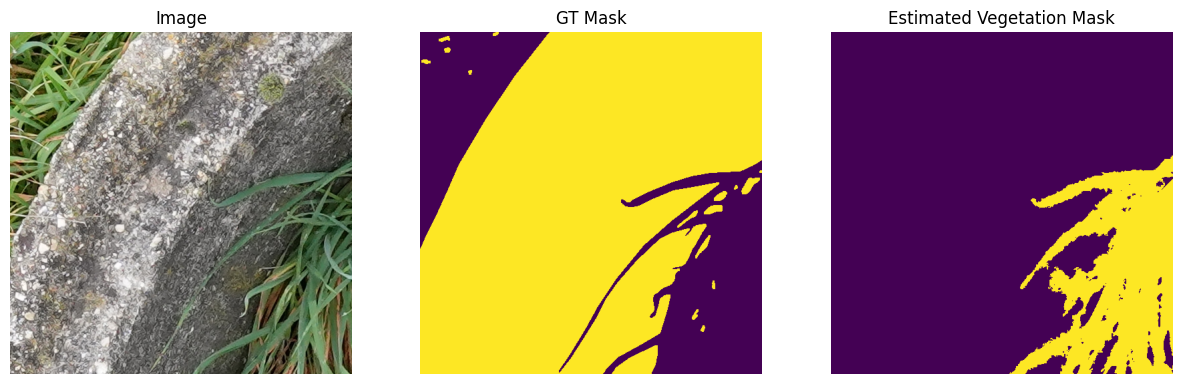

In [47]:
idx = 0

sample = dataset["train"][idx]

image = np.array(sample["image"])
mask = np.array(sample["mask"])

# VegAnn: vegetation/foreground = 0, background = 255
gt_mask = mask == 0

gt_box = get_gt_box(gt_mask)
auto_box, estimated_veg_mask = get_vegetation_box_from_image(image)

print("Species:", sample["Species"])
print("GT box:", gt_box)
print("Auto box:", auto_box)

plt.figure(figsize=(15, 5))

plt.subplot(131)
plt.imshow(image)
plt.title("Image")
plt.axis("off")

plt.subplot(132)
plt.imshow(gt_mask)
plt.title("GT Mask")
plt.axis("off")

plt.subplot(133)
plt.imshow(estimated_veg_mask)
plt.title("Estimated Vegetation Mask")
plt.axis("off")

plt.show()

In [14]:
#Loading AGRICLIP 
agriclip_paths = [
    "/home/zahranadeem/AgriCLIP",
    "/home/zahranadeem/AgriCLIP/AgriCLIP_alignment",
    "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP",
    "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment",
]

for p in agriclip_paths:
    if os.path.exists(p) and p not in sys.path:
        sys.path.append(p)

print("Paths added")

Paths added


In [15]:
#Import AgriCLIP modules 
from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

print("AgriCLIP modules imported")

AgriCLIP modules imported


In [16]:
#Loading DINO 
model = torch.hub.load(
    "facebookresearch/dino:main",
    "dino_resnet50",
    pretrained=True
)

dino_path_candidates = [
    "/home/zahranadeem/AgriCLIP/Weights/dino_pretrain.pth",
    "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/Weights/dino_pretrain.pth",
]

dino_path = None

for p in dino_path_candidates:
    if os.path.exists(p):
        dino_path = p
        break

print("DINO path:", dino_path)

model.load_state_dict(
    torch.load(dino_path, map_location="cpu")
)

model = model.to(device)
model.eval()

def forward_features(x):
    return model(x)

model.forward_features = forward_features

print("DINO loaded")

Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/zahranadeem/thesis/agriclip_sam2/agriclip_env/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


DINO path: /home/zahranadeem/AgriCLIP/Weights/dino_pretrain.pth
DINO loaded


In [17]:
#Load Fine tuned AgriCLIP aligner 
text_to_concept = TextToConcept(model, "Dino")

aligner_path = "/home/zahranadeem/thesis/vegann_plantvillage_aligner.pth"

text_to_concept.load_linear_aligner(aligner_path)

print("VegAnn + PlantVillage fine-tuned aligner loaded")

VegAnn + PlantVillage fine-tuned aligner loaded


In [18]:
#AgriCLIP species prediction 
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

species_list = sorted(list(set(dataset["train"]["Species"])))

species_classifier = text_to_concept.get_zero_shot_classifier(
    species_list,
    prompts=[
        "An agricultural image showing {} plants."
    ]
)

img_tensor = transform(sample["image"]).unsqueeze(0).to(device)

with torch.no_grad():
    logits = species_classifier(img_tensor)

scores = logits.squeeze().cpu().numpy()

top5 = np.argsort(scores)[-5:][::-1]

print("Ground Truth:", sample["Species"])
print("\nAgriCLIP Top-5:")

for i in top5:
    print(species_list[i], scores[i])

predicted_species = species_list[top5[0]]

print("\nPredicted species:", predicted_species)

Ground Truth: Mix

AgriCLIP Top-5:
Bean 0.5542761
Na 0.5493031
Raspberry 0.5460218
Potato 0.5446335
Rice 0.5342288

Predicted species: Bean


In [36]:
#Creating automatic vegetation box without GT 
#Image itself is used to estimate vegetation location, while 
#Agriclip supplies the semantic label
from scipy import ndimage
import numpy as np

def get_vegetation_box_from_image(image, padding=10, percentile=70):
    img = image.astype(np.float32) / 255.0

    r = img[:, :, 0]
    g = img[:, :, 1]
    b = img[:, :, 2]

    exg = 2 * g - r - b
    threshold = np.percentile(exg, percentile)

    veg_mask = exg > threshold

    labeled, num = ndimage.label(veg_mask)

    if num == 0:
        H, W = image.shape[:2]
        return np.array([W//4, H//4, 3*W//4, 3*H//4]), veg_mask

    sizes = ndimage.sum(veg_mask, labeled, range(1, num + 1))
    largest_label = np.argmax(sizes) + 1
    largest_mask = labeled == largest_label

    ys, xs = np.where(largest_mask)

    H, W = image.shape[:2]

    x1 = max(xs.min() - padding, 0)
    y1 = max(ys.min() - padding, 0)
    x2 = min(xs.max() + padding, W - 1)
    y2 = min(ys.max() + padding, H - 1)

    box = np.array([x1, y1, x2, y2])

    return box, largest_mask

In [38]:
agriclip_results = []

for idx in tqdm(range(50)):

    sample = dataset["train"][idx]

    image = np.array(sample["image"])
    mask = np.array(sample["mask"])

    gt_mask = mask == 0

    if gt_mask.sum() == 0:
        continue

    auto_box, estimated_veg_mask = get_vegetation_box_from_image(
        image,
        padding=10,
        percentile=70
    )

    pred_mask = run_sam2_box_prompt(image, auto_box)

    iou, dice = compute_iou_dice(pred_mask, gt_mask)

    agriclip_results.append({
        "idx": idx,
        "Species": sample["Species"],
        "AgriCLIP_Box_IoU": iou,
        "AgriCLIP_Box_Dice": dice
    })

agriclip_results_50 = pd.DataFrame(agriclip_results)

agriclip_results_50.head()

100%|██████████| 50/50 [00:01<00:00, 26.55it/s]


,idx,Species,AgriCLIP_Box_IoU,AgriCLIP_Box_Dice
0,0,Mix,0.006008,0.011944
1,1,Mix,0.003094,0.006168
2,2,Mix,0.000056,0.000111
3,3,Mix,0.060152,0.113479
4,4,Mix,0.142437,0.249356


In [40]:
agriclip_mean_iou = agriclip_results_50["AgriCLIP_Box_IoU"].mean()
agriclip_mean_dice = agriclip_results_50["AgriCLIP_Box_Dice"].mean()

print(f"AgriCLIP + SAM2 Mean IoU: {agriclip_mean_iou*100:.2f}%")
print(f"AgriCLIP + SAM2 Mean Dice: {agriclip_mean_dice*100:.2f}%")

AgriCLIP + SAM2 Mean IoU: 6.20%
AgriCLIP + SAM2 Mean Dice: 10.42%


In [37]:
#Generate AgriCLIP guided SAM2 box 

agriclip_box, estimated_veg_mask = get_vegetation_box_from_image(image)

print("AgriCLIP semantic label:", predicted_species)
print("Generated SAM2 box:", agriclip_box)

AgriCLIP semantic label: Bean
Generated SAM2 box: [  0   0 450 433]


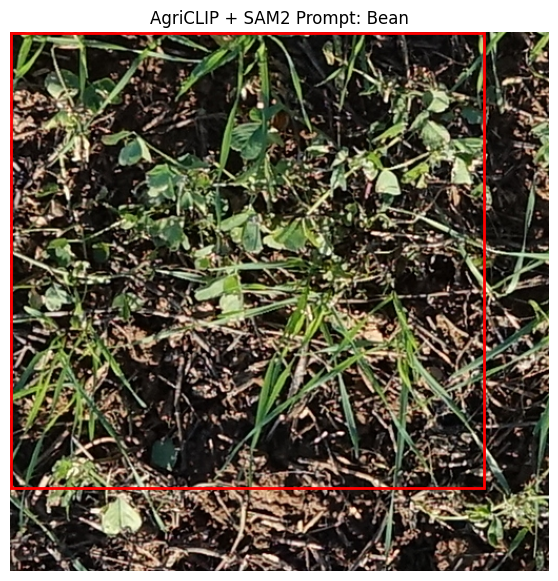

In [39]:
#Visualize the generated box 
import matplotlib.patches as patches

x1, y1, x2, y2 = agriclip_box

fig, ax = plt.subplots(figsize=(7,7))

ax.imshow(image)

rect = patches.Rectangle(
    (x1, y1),
    x2-x1,
    y2-y1,
    linewidth=2,
    edgecolor="red",
    facecolor="none"
)

ax.add_patch(rect)

ax.set_title(f"AgriCLIP + SAM2 Prompt: {predicted_species}")
ax.axis("off")

plt.show()

In [21]:
def compute_iou_dice(pred_mask, gt_mask):
    pred = pred_mask.astype(bool)
    gt = gt_mask.astype(bool)

    intersection = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()

    iou = intersection / union if union > 0 else 0
    dice = (2 * intersection) / (pred.sum() + gt.sum()) if (pred.sum() + gt.sum()) > 0 else 0

    return iou, dice

In [22]:
def get_gt_box(gt_mask, padding=0):
    ys, xs = np.where(gt_mask)

    if len(xs) == 0:
        return None

    H, W = gt_mask.shape

    x1 = max(xs.min() - padding, 0)
    y1 = max(ys.min() - padding, 0)
    x2 = min(xs.max() + padding, W - 1)
    y2 = min(ys.max() + padding, H - 1)

    return np.array([x1, y1, x2, y2])

In [23]:
def run_sam2_point_prompt(image):
    H, W = image.shape[:2]

    point = np.array([[W//2, H//2]])
    label = np.array([1])

    predictor.set_image(image)

    masks, scores, logits = predictor.predict(
        point_coords=point,
        point_labels=label,
        multimask_output=True
    )

    best_idx = scores.argmax()
    pred_mask = masks[best_idx] > 0

    return pred_mask

In [26]:
def run_sam2_point_prompt(image):
    H, W = image.shape[:2]

    point = np.array([[W//2, H//2]])
    label = np.array([1])

    predictor.set_image(image)

    masks, scores, logits = predictor.predict(
        point_coords=point,
        point_labels=label,
        multimask_output=True
    )

    best_idx = scores.argmax()
    pred_mask = masks[best_idx] > 0

    return pred_mask

In [27]:
def run_sam2_box_prompt(image, box):
    predictor.set_image(image)

    masks, scores, logits = predictor.predict(
        box=box,
        multimask_output=True
    )

    best_idx = scores.argmax()
    pred_mask = masks[best_idx] > 0

    return pred_mask

In [28]:
N = 50
all_results = []

for idx in tqdm(range(N)):

    sample = dataset["train"][idx]

    image = np.array(sample["image"])
    mask = np.array(sample["mask"])

    gt_mask = mask == 0

    if gt_mask.sum() == 0:
        continue

    # Point prompt
    point_pred = run_sam2_point_prompt(image)
    point_iou, point_dice = compute_iou_dice(point_pred, gt_mask)

    # Box prompt
    gt_box = get_gt_box(gt_mask)

    if gt_box is None:
        continue

    box_pred = run_sam2_box_prompt(image, gt_box)
    box_iou, box_dice = compute_iou_dice(box_pred, gt_mask)

    all_results.append({
        "idx": idx,
        "Species": sample["Species"],
        "Point_IoU": point_iou,
        "Point_Dice": point_dice,
        "Box_IoU": box_iou,
        "Box_Dice": box_dice
    })

results_50 = pd.DataFrame(all_results)

100%|██████████| 50/50 [00:02<00:00, 16.75it/s]


In [29]:
results_50.head()

,idx,Species,Point_IoU,Point_Dice,Box_IoU,Box_Dice
0,0,Mix,0.943637,0.971001,0.867146,0.928847
1,1,Mix,0.000000,0.000000,0.011068,0.021894
2,2,Mix,0.078397,0.145395,0.000938,0.001874
3,3,Mix,0.941947,0.970106,0.957374,0.978223
4,4,Mix,0.001945,0.003883,0.072526,0.135244


In [30]:
summary = pd.DataFrame({
    "Method": [
        "SAM2 + Point Prompt",
        "SAM2 + GT Box Prompt"
    ],
    "Mean IoU": [
        results_50["Point_IoU"].mean(),
        results_50["Box_IoU"].mean()
    ],
    "Mean Dice": [
        results_50["Point_Dice"].mean(),
        results_50["Box_Dice"].mean()
    ]
})

summary

,Method,Mean IoU,Mean Dice
0,SAM2 + Point Prompt,0.105227,0.123633
1,SAM2 + GT Box Prompt,0.412786,0.503835


In [31]:
summary_percent = summary.copy()

summary_percent["Mean IoU"] = summary_percent["Mean IoU"].apply(lambda x: f"{x*100:.2f}%")
summary_percent["Mean Dice"] = summary_percent["Mean Dice"].apply(lambda x: f"{x*100:.2f}%")

summary_percent

,Method,Mean IoU,Mean Dice
0,SAM2 + Point Prompt,10.52%,12.36%
1,SAM2 + GT Box Prompt,41.28%,50.38%


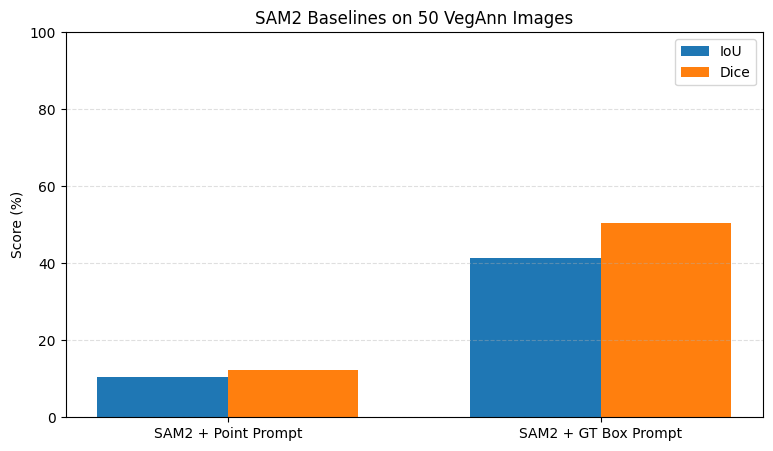

In [32]:
methods = summary["Method"].tolist()
iou_scores = [x * 100 for x in summary["Mean IoU"].tolist()]
dice_scores = [x * 100 for x in summary["Mean Dice"].tolist()]

x = np.arange(len(methods))
width = 0.35

plt.figure(figsize=(9,5))

plt.bar(x - width/2, iou_scores, width, label="IoU")
plt.bar(x + width/2, dice_scores, width, label="Dice")

plt.xticks(x, methods)
plt.ylabel("Score (%)")
plt.title("SAM2 Baselines on 50 VegAnn Images")
plt.ylim(0,100)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.show()